# CS324 Deep Learning · Assignment 1
## NumPy perceptron and multi-layer perceptron: verified experiments

**Student:** Fan Xiaole (Justin Fan) · **Student number:** 12412307

This notebook complements the revised written report. It contains the
required full-batch and stochastic gradient descent learning curves,
batch-size analysis, implementation checks, and additional controlled
experiments. The implementation and original submission are preserved.

**Execution policy.** Opening or executing this notebook reads saved
experiment results and figures. Training is implemented in the supplied
Python scripts; an optional cell below reruns them explicitly. Tables
read exact JSON values rather than transcribing rounded training logs.

Source specifications: `Assignment_1.pdf` and
`perceptron_tutorial.pdf`. The supplied course handouts are retained
locally under `references/` and omitted from the submission ZIP.

In [1]:
import hashlib
import html
import json
import math
import os
import subprocess
import sys
from pathlib import Path

from IPython.display import HTML, Image, Markdown, display

# Support both a kernel launched in this directory and the project root.
HERE = Path.cwd()
BASE = HERE if (HERE / "results").is_dir() else HERE / "report_revision"
assert (BASE / "results").is_dir(), "Launch from report_revision or the project root."
ROOT = BASE.parent

def read_result(name):
    path = BASE / "results" / name
    assert path.is_file(), f"Missing {path}; run its experiment script first."
    return json.loads(path.read_text())

def table(headers, rows):
    def cell(value):
        return html.escape(str(value))
    head = "".join(f"<th style='text-align:left;padding:6px'>{cell(h)}</th>" for h in headers)
    body = "".join("<tr>" + "".join(f"<td style='padding:6px'>{cell(v)}</td>" for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))

def figure(name, caption):
    path = BASE / "figures" / name
    assert path.is_file(), f"Missing figure: {path}"
    display(Image(filename=str(path), width=1000))
    display(Markdown(caption))

perceptron = read_result("perceptron.json")
print("Saved perceptron results loaded. MLP results load in Part II.")

Saved perceptron results loaded. MLP results load in Part II.


## Reproduce the results

Select a Python 3.11 kernel from an environment containing the
dependencies in `report_revision/requirements.txt`. The supplied
notebook uses the portable kernel name `python3`; it does not require
the author's local `mldl` environment name. To install dependencies,
run `python -m pip install -r report_revision/requirements.txt` from
the project root. Then run the experiment scripts from the project
root and regenerate and execute this notebook. The original training
routines remain the source of the required baseline results. A kernel
may run from either the project root or the `report_revision` directory.

The cell below is intentionally disabled during normal notebook
execution. Set `RUN_EXPERIMENTS = True` only when requesting a fresh
run. The scripts also regenerate the figures shown below.

In [2]:
RUN_EXPERIMENTS = False
if RUN_EXPERIMENTS:
    experiment_env = os.environ.copy()
    experiment_env.update({"OPENBLAS_NUM_THREADS": "1", "OMP_NUM_THREADS": "1", "PYTHONDONTWRITEBYTECODE": "1"})
    for script in ("perceptron_experiments.py", "mlp_experiments.py"):
        subprocess.run([sys.executable, str(BASE / script)], cwd=ROOT, env=experiment_env, check=True)
    print("Experiments regenerated. Run all cells again to reload their results.")
else:
    print("Training skipped: this execution uses the supplied saved results.")

Training skipped: this execution uses the supplied saved results.


## Part I · Batch perceptron and Gaussian overlap

Each class has 100 independent two-dimensional Gaussian samples, with
exactly 80 training and 20 test samples per class. Labels are $-1,+1$.
The model augments each input with a constant bias coordinate and
predicts the sign of its linear score.

For margin violations $M=\{i:y_i\tilde{x}_i^T w\leq0\}$, the supplied
implementation updates
$$w\leftarrow w+\eta\,\frac{1}{|M|}\sum_{i\in M}y_i\tilde{x}_i.$$
It performs one update from all violating samples per epoch, and stops
if there are none. Averaging over the current violating set is the
implementation's update convention; this changes the effective step
size relative to a summed perceptron criterion.

In [3]:
rows = []
for result in perceptron["baselines"]:
    last = result["history"][-1]
    rows.append([
        result["title"],
        f"{result['variance']:.2f}",
        f"{last['train_accuracy']:.2%}",
        f"{last['test_accuracy']:.2%}",
        f"{result['population_oracle_accuracy']:.2%}",
        result["trajectory_matches_original_weights_exactly"],
    ])
table(["Case", "Variance", "Train accuracy", "Test accuracy", "Population oracle accuracy", "Original weights reproduced"], rows)

Case,Variance,Train accuracy,Test accuracy,Population oracle accuracy,Original weights reproduced
Well separated,0.25,100.00%,100.00%,100.00%,True
Close means,0.25,90.62%,90.00%,92.14%,True
High variance,2.00,93.75%,87.50%,97.72%,True


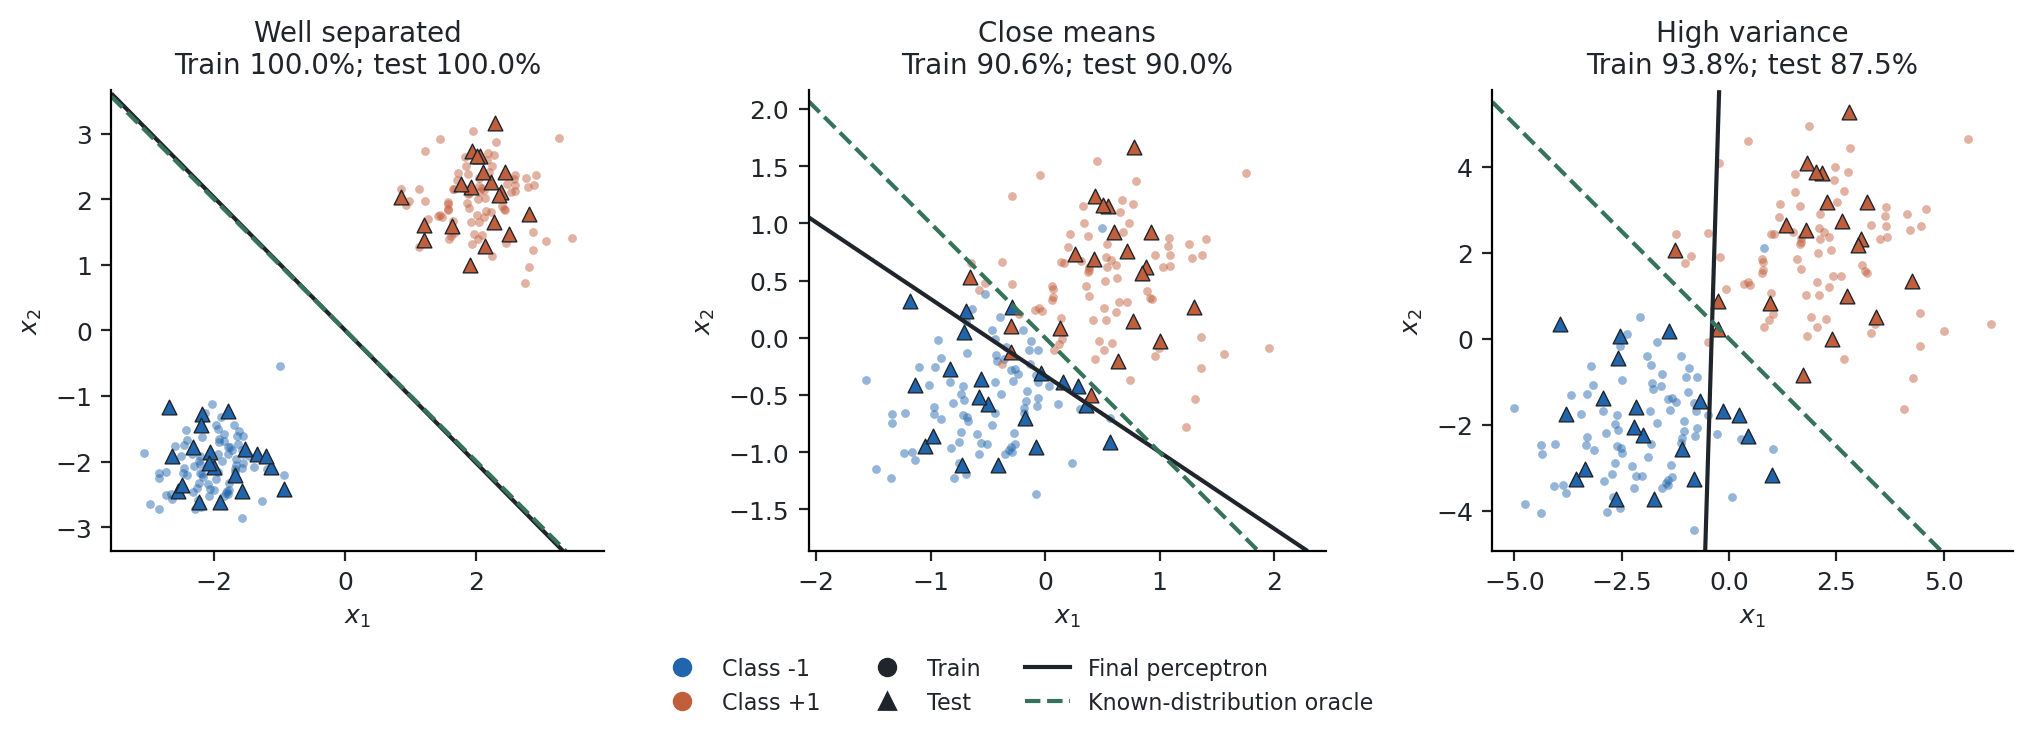

**Figure P1.** Gaussian samples and final linear decision boundaries. Training and test samples are distinguished; the population oracle provides context for overlap.

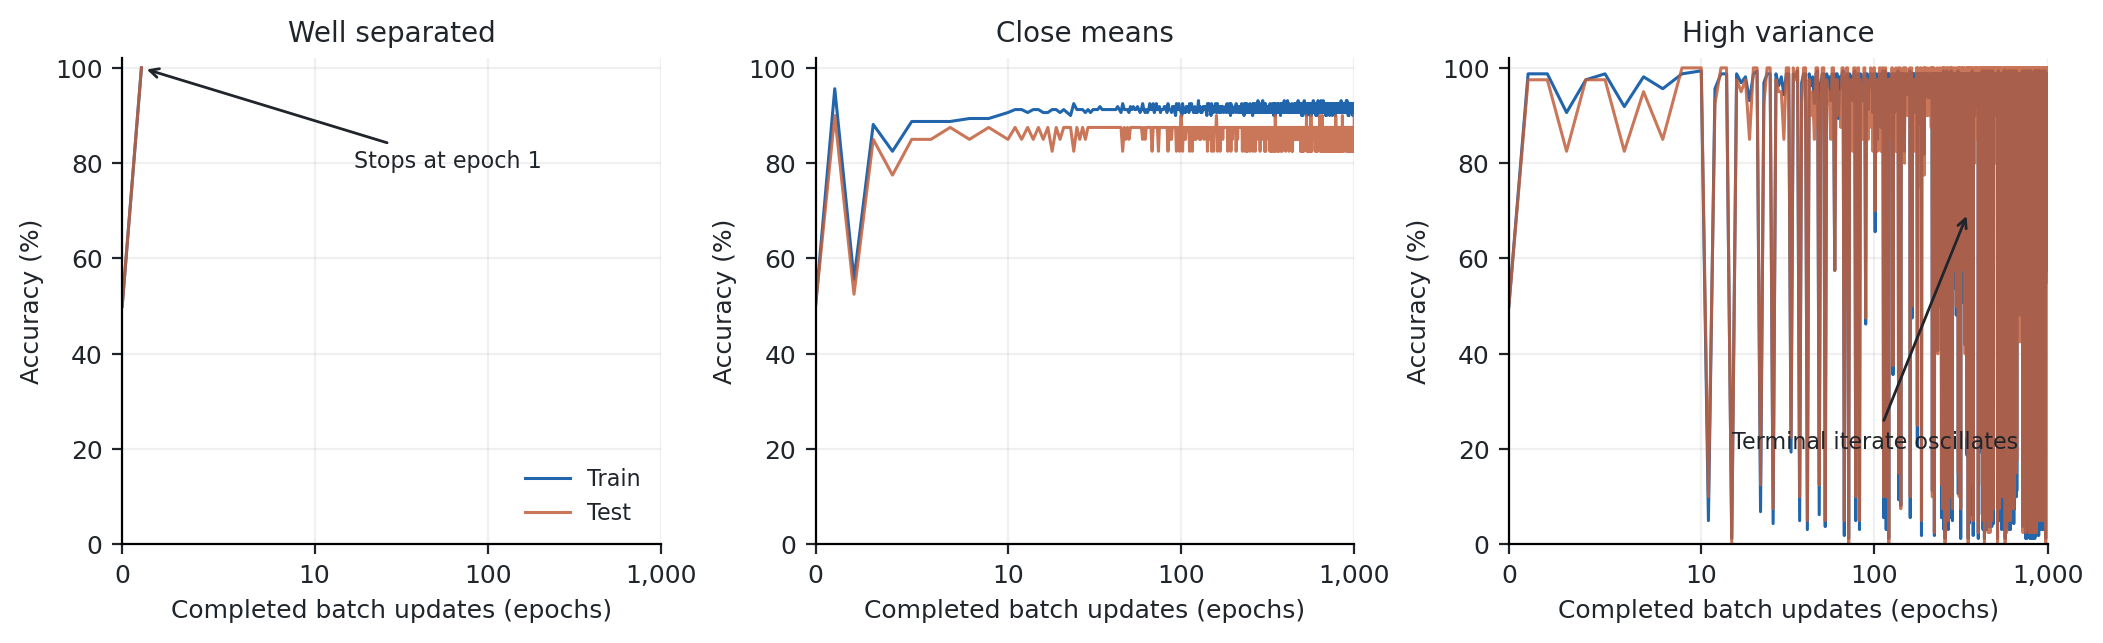

**Figure P2.** Training trajectories distinguish reaching a zero-violation stopping condition from exhausting the epoch budget on overlapping data.

In [4]:
figure("perceptron_boundaries.png", "**Figure P1.** Gaussian samples and final linear decision boundaries. Training and test samples are distinguished; the population oracle provides context for overlap.")
figure("perceptron_trajectories.png", "**Figure P2.** Training trajectories distinguish reaching a zero-violation stopping condition from exhausting the epoch budget on overlapping data.")

### Extension · Separate population overlap from optimization failure

For equal class priors and shared isotropic covariance $\sigma^2I$,
the optimal population classifier is already linear. Its expected
accuracy is
$$A_{\mathrm{oracle}}=\Phi\!\left(\frac{\|\mu_+-\mu_-\|}{2\sigma}\right).$$
Here $\Phi$ is the standard normal cumulative distribution function.
Reducing the distance between means or increasing variance reduces the
separation in units of standard deviation. Overlap therefore creates
irreducible population error; a nonlinear boundary does not generally
eliminate it. A finite test sample can score above or below this
population expectation. The heatmap means aggregate five paired
seeds; seed-level values and sample standard deviations are stored in
the JSON results. In each paired run, the perceptron and oracle are
evaluated on identical held-out points. Perceptron final-iterate
behavior additionally reflects the optimization rule and stopping
budget.

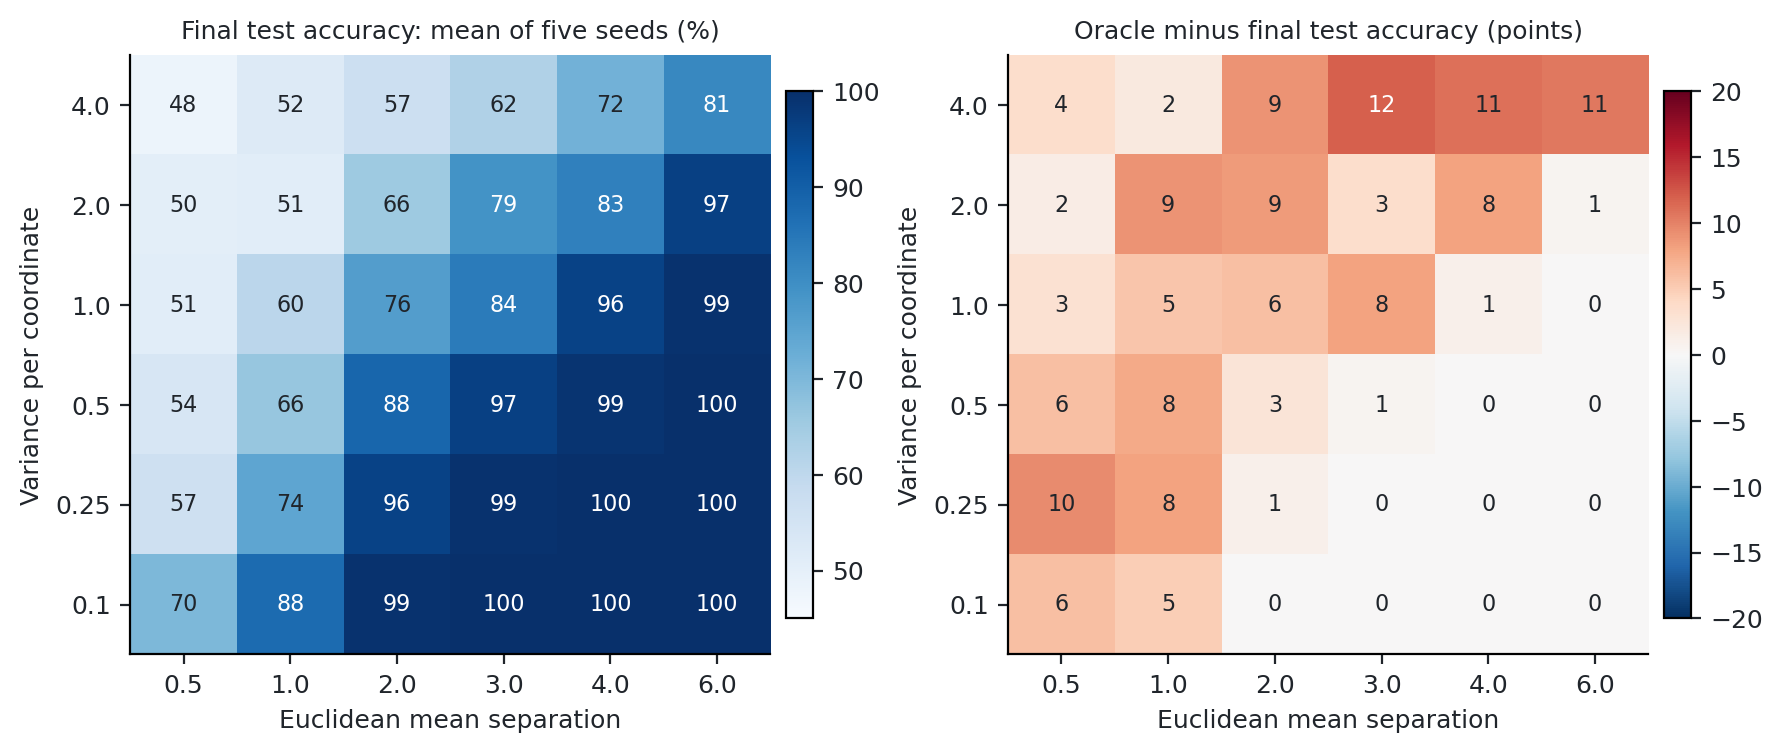

**Figure P3.** Controlled separation/variance sweep: mean perceptron test accuracy and the mean empirical held-out oracle-minus-perceptron accuracy gap. Both classifiers use identical held-out points in each of five paired seeds; seed-level values and sample SD are stored in JSON.

Perceptron sweep seeds: [0, 1, 2, 3, 4]
Perceptron experiment seconds: 2.29


In [5]:
figure("perceptron_separation_sweep.png", "**Figure P3.** Controlled separation/variance sweep: mean perceptron test accuracy and the mean empirical held-out oracle-minus-perceptron accuracy gap. Both classifiers use identical held-out points in each of five paired seeds; seed-level values and sample SD are stored in JSON.")
print("Perceptron sweep seeds:", perceptron["sweep"]["seeds"])
print("Perceptron experiment seconds:", round(perceptron["elapsed_seconds"], 3))

## Part II · NumPy MLP, forward pass and backpropagation

The required default network is `Linear(2,20) → ReLU → Linear(20,2)
→ Softmax`. It has 102 trainable parameters. The moons dataset has
1,000 samples, noise 0.2, and a random, stratified 800/200 train/test
split. Labels are two-dimensional one-hot vectors. All neural-network
calculations use NumPy; scikit-learn generates and splits the data.

In row-oriented batch notation,
$$H=\max(0,XW_1+b_1),\quad Z=HW_2+b_2,\quad P=\mathrm{softmax}(Z).$$
Softmax subtracts each row's largest logit before exponentiation.
For a batch of $B$ samples, mean cross entropy is
$$L=-\frac1B\sum_{i=1}^{B}\sum_cY_{ic}\log P_{ic}.$$
The combined softmax/cross-entropy logit gradient is
$$dZ=(P-Y)/B.$$
Consequently $dW_2=H^TdZ$, $db_2=\sum_i dZ_i$, and
$$dH=dZW_2^T,\quad dA_1=dH\odot\mathbf{1}_{XW_1+b_1>0},
\quad dW_1=X^TdA_1.$$
The bias gradient is the corresponding row sum. The batch-average
factor is applied once. For each affine layer, the returned gradient
uses the pre-update weights; all parameters update after backpropagation.

In [6]:
mlp = read_result("mlp.json")
assert len(mlp["runs"]) == 70, "Expected 5 seeds × 7 batch sizes × 2 budgets."
config = mlp["config"]
table(["Setting", "Value"], [
    ["Hidden units", config["hidden_units"]],
    ["Learning rate", config["learning_rate"]],
    ["Required epoch budget", config["equal_epoch_budget"]],
    ["Extension update budget", config["equal_update_budget"]],
    ["Dataset / train / test sizes", f"{config['n_samples']} / {config['train_size']} / {config['test_size']}"],
    ["Noise", config["noise"]],
    ["Batch sizes", config["batch_sizes"]],
    ["Pipeline seeds", config["seeds"]],
    ["Initialization", config["weight_initialization"]],
])

def run(budget, batch, seed=42):
    return next(item for item in mlp["runs"] if item["budget"] == budget and item["batch_size"] == batch and item["seed"] == seed)

Setting,Value
Hidden units,[20]
Learning rate,0.01
Required epoch budget,1500
Extension update budget,1500
Dataset / train / test sizes,1000 / 800 / 200
Noise,0.2
Batch sizes,"[1, 8, 16, 32, 64, 128, 800]"
Pipeline seeds,"[0, 1, 2, 3, 42]"
Initialization,0.01 * np.random.randn; zero bias


### Extension · Verify gradients numerically

Central finite differences perturb one parameter at a time:
$$g_j^{\mathrm{num}}=\frac{L(\theta+\epsilon e_j)-L(\theta-\epsilon e_j)}{2\epsilon}.$$
The checks cover every weight and bias in both a one-hidden-layer and
a two-hidden-layer network, with batch sizes 1 and 7. The relative
error below is the norm of the analytic/numerical difference divided
by the sum of their norms (with a small denominator floor). Agreement
supports the derivative and batch-normalization implementation on
these checks; it is not a proof for every possible input.

In [7]:
verification = mlp["verification"]
checks = verification["tensors"]
table(["Hidden widths", "Batch", "Layer", "Parameter", "Count", "Max absolute error", "Relative L2 error"], [
    [item["hidden"], item["batch_size"], item["layer_index"], item["parameter"], item["parameter_count"], f"{item['max_absolute_error']:.3e}", f"{item['relative_l2_error']:.3e}"]
    for item in checks
])
print("Central-difference epsilon:", verification["epsilon"])
print("Maximum absolute error:", verification["max_absolute_error"])
print("Maximum relative L2 error:", verification["max_relative_l2_error"])
assert verification["max_absolute_error"] < 1e-7
assert verification["max_relative_l2_error"] < 1e-5
print("Numerical checks passed the notebook's stated tolerances.")

Hidden widths,Batch,Layer,Parameter,Count,Max absolute error,Relative L2 error
[4],1,0,weight,8,1.069e-10,1.150e-10
[4],1,0,bias,4,1.586e-10,1.839e-10
[4],1,2,weight,8,8.871e-11,2.008e-10
[4],1,2,bias,2,8.875e-11,9.266e-11
[4],7,0,weight,8,9.409e-11,8.137e-10
[4],7,0,bias,4,7.796e-11,2.942e-10
[4],7,2,weight,8,6.891e-11,2.794e-10
[4],7,2,bias,2,5.131e-11,6.614e-11
"[4, 3]",1,0,weight,8,6.454e-11,2.316e-09
"[4, 3]",1,0,bias,4,4.984e-11,1.440e-09


Central-difference epsilon: 1e-06
Maximum absolute error: 1.5862668123478585e-10
Maximum relative L2 error: 7.926214683403031e-09
Numerical checks passed the notebook's stated tolerances.


**Numerical limitation retained from the original implementation.**
Probability clipping in the reported cross entropy prevents taking
`log(0)`, but caps the reported loss for extreme wrong predictions.
The backward pass still uses the ordinary, unclipped softmax/cross-entropy
derivative. This distinction is documented below; the gradient checks
use the non-clipped regime. A logits-based log-sum-exp loss would
address this extreme-input limitation. The existing implementation is
preserved so the report's baseline remains comparable with the
original submission.

In [8]:
caveat = verification["clipped_loss_caveat"]
table(["Extreme-input check", "Value"], [
    ["Logits", caveat["logits"]],
    ["One-hot target", caveat["target"]],
    ["Original clipped probability loss", f"{caveat['reported_clipped_loss']:.6f}"],
    ["Stable logits-based cross entropy", f"{caveat['stable_logits_loss']:.6f}"],
])

Extreme-input check,Value
Logits,"[[-100.0, 100.0]]"
One-hot target,"[[1.0, 0.0]]"
Original clipped probability loss,27.631021
Stable logits-based cross entropy,200.000000


### Required default experiments · Full batch and SGD

The learning rate is 0.01, hidden width is 20, and each run completes
1,500 epochs. Seed 42 fixes dataset generation, split, initialization,
and shuffle order for the default comparison. In the original
trainer, `max_steps` counts **epochs**, not individual optimizer
updates. Its recorded step 0 follows the first completed epoch;
all revised epoch labels therefore use `steps + 1`.

Training and test metrics are evaluated on the same parameter state.
Final results use the last budget endpoint, without picking a
checkpoint from test performance.

Method,Batch,Updates,Train accuracy,Test accuracy,Train loss,Test loss
Full-batch GD,800,1500,82.50%,87.00%,0.397971,0.356617
SGD,1,1200000,97.50%,98.50%,0.074450,0.043268


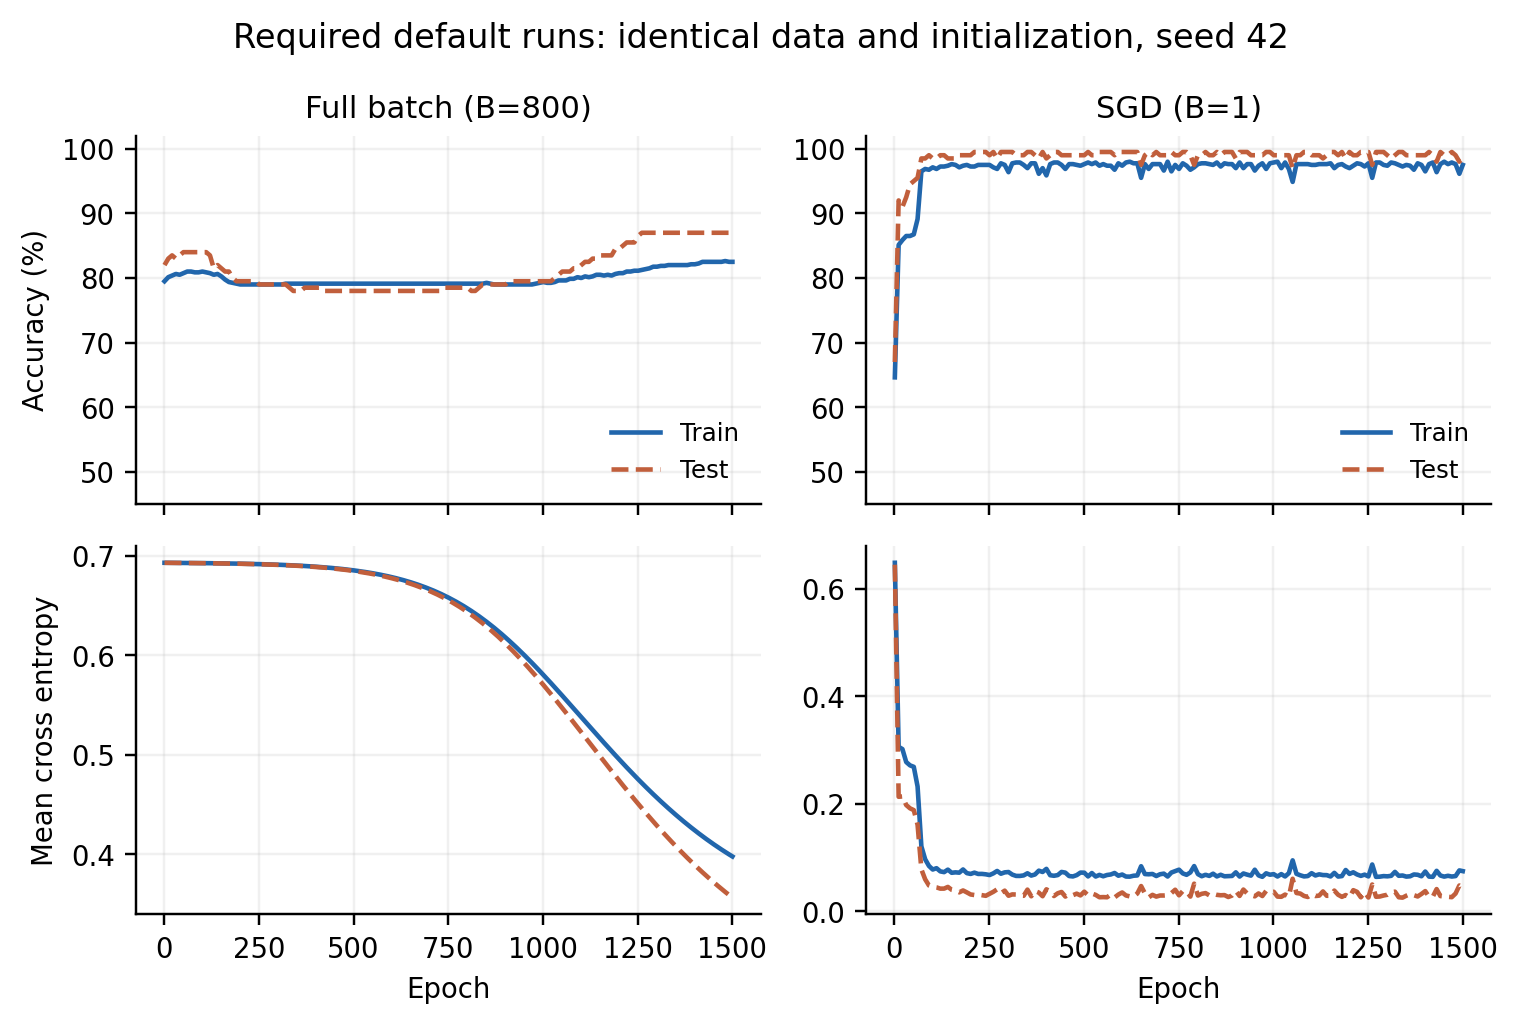

**Figure M1.** Required default runs: training and test accuracy (top), training and test loss (bottom), shown separately for full-batch GD and SGD.

In [9]:
table(["Method", "Batch", "Updates", "Train accuracy", "Test accuracy", "Train loss", "Test loss"], [
    [name, batch, run("equal_epoch", batch)["optimizer_updates"],
     f"{run('equal_epoch', batch)['final']['train_accuracy']:.2%}",
     f"{run('equal_epoch', batch)['final']['test_accuracy']:.2%}",
     f"{run('equal_epoch', batch)['final']['train_loss']:.6f}",
     f"{run('equal_epoch', batch)['final']['test_loss']:.6f}"]
    for name, batch in [("Full-batch GD", 800), ("SGD", 1)]
])
figure("mlp_default_curves.png", "**Figure M1.** Required default runs: training and test accuracy (top), training and test loss (bottom), shown separately for full-batch GD and SGD.")

In [10]:
table(["Seed-42 epoch-budget batch", "Minimum true-class p (train)", "Minimum true-class p (test)", "Clipped true-class counts (train / test)"], [
    [batch,
     f"{run('equal_epoch', batch)['diagnostics']['train']['minimum_true_class_probability']:.3e}",
     f"{run('equal_epoch', batch)['diagnostics']['test']['minimum_true_class_probability']:.3e}",
     f"{run('equal_epoch', batch)['diagnostics']['train']['clipped_true_class_count']} / {run('equal_epoch', batch)['diagnostics']['test']['clipped_true_class_count']}"]
    for batch in config["batch_sizes"]
])
display(Markdown("**Observed numerical context.** These are diagnostics at the recorded final checkpoints. They place the extreme-logit limitation in context; they do not monitor every intermediate training update."))

Seed-42 epoch-budget batch,Minimum true-class p (train),Minimum true-class p (test),Clipped true-class counts (train / test)
1,3.054e-02,1.829e-01,0 / 0
8,1.026e-02,2.399e-01,0 / 0
16,2.223e-02,2.678e-01,0 / 0
32,3.272e-02,6.734e-02,0 / 0
64,5.026e-02,7.781e-02,0 / 0
128,5.420e-02,7.848e-02,0 / 0
800,1.807e-01,2.130e-01,0 / 0


**Observed numerical context.** These are diagnostics at the recorded final checkpoints. They place the extreme-logit limitation in context; they do not monitor every intermediate training update.

## Part III · Batch-size influence and comparison budgets

Each epoch visits all 800 training examples. The number of parameter
updates per epoch is $\lceil800/B\rceil$; a smaller final batch is used
when $B$ does not divide 800. Therefore, holding epochs fixed controls
sample exposure but does not control update count. The required sweep
retains the default 1,500-epoch setting.

An additional sweep holds updates fixed at 1,500. This controls the
number of optimization steps but does **not** equalize processed
observations, floating-point operations, or wall-clock time. These two
protocols answer different questions and should be interpreted together.

Batch,Updates/epoch,"1,500-epoch updates",Train accuracy,Test accuracy,Test loss
1,800,1200000,97.50%,98.50%,0.043268
8,100,150000,97.62%,99.00%,0.032779
16,50,75000,97.12%,98.50%,0.046950
32,25,37500,86.50%,94.50%,0.187833
64,13,19500,86.12%,92.50%,0.206788
128,7,10500,85.62%,92.00%,0.213687
800,1,1500,82.50%,87.00%,0.356617


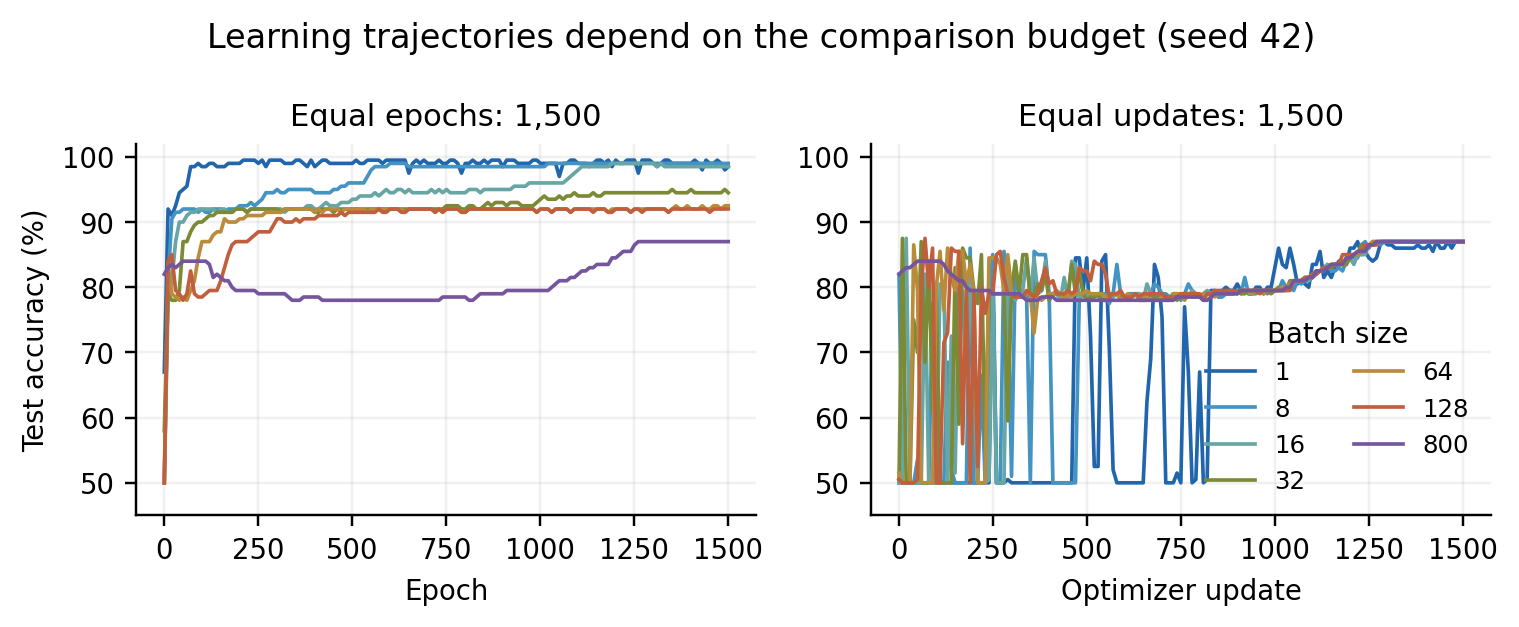

**Figure M2.** Seed-42 test-accuracy trajectories. Left: the required runs with a 1,500-epoch budget. Right: separate training runs with a 1,500-optimizer-update budget. This is a descriptive test sweep; no hyperparameter is selected from it.

In [11]:
table(["Batch", "Updates/epoch", "1,500-epoch updates", "Train accuracy", "Test accuracy", "Test loss"], [
    [batch, math.ceil(800 / batch), run("equal_epoch", batch)["optimizer_updates"],
     f"{run('equal_epoch', batch)['final']['train_accuracy']:.2%}",
     f"{run('equal_epoch', batch)['final']['test_accuracy']:.2%}",
     f"{run('equal_epoch', batch)['final']['test_loss']:.6f}"]
    for batch in config["batch_sizes"]
])
figure("mlp_batch_trajectories.png", "**Figure M2.** Seed-42 test-accuracy trajectories. Left: the required runs with a 1,500-epoch budget. Right: separate training runs with a 1,500-optimizer-update budget. This is a descriptive test sweep; no hyperparameter is selected from it.")

In [12]:
table(["Batch", "Fixed-update updates", "Samples processed", "Equivalent epochs", "Train accuracy", "Test accuracy", "Test loss"], [
    [batch, run("equal_update", batch)["optimizer_updates"],
     run("equal_update", batch)["samples_seen"],
     f"{run('equal_update', batch)['epoch_equivalent']:.3f}",
     f"{run('equal_update', batch)['final']['train_accuracy']:.2%}",
     f"{run('equal_update', batch)['final']['test_accuracy']:.2%}",
     f"{run('equal_update', batch)['final']['test_loss']:.6f}"]
    for batch in config["batch_sizes"]
])
print("Full-batch cross-run maximum parameter difference:", verification["equal_update_vs_original_fullbatch_seed42_max_parameter_difference"])
assert verification["equal_update_vs_original_fullbatch_seed42_max_parameter_difference"] < 1e-12

Batch,Fixed-update updates,Samples processed,Equivalent epochs,Train accuracy,Test accuracy,Test loss
1,1500,1500,1.875,82.12%,87.00%,0.360430
8,1500,12000,15.000,82.50%,87.00%,0.356775
16,1500,24000,30.000,82.50%,87.00%,0.356725
32,1500,48000,60.000,82.62%,87.00%,0.356646
64,1500,92320,115.400,82.62%,87.00%,0.356865
128,1500,171456,214.320,82.62%,87.00%,0.356807
800,1500,1200000,1500.000,82.50%,87.00%,0.356617


Full-batch cross-run maximum parameter difference: 0.0


### Extension · Repeat the complete pipeline across five seeds

Each seed jointly changes the generated dataset, split, network
initialization, and shuffle order. Within a seed, batch-size
comparisons share these settings. The plotted mean and sample standard
deviation summarize total pipeline variation; they do not isolate
initialization noise or form confidence intervals. Test results are
descriptive across the prespecified sweep. Selecting a batch size or
architecture would require a validation split and an independently
assessed final test result.

Budget,Batch,Seeds,Mean test accuracy,Sample SD (percentage points),Mean test loss
equal_epoch,1,5,92.80%,4.881,0.161792
equal_epoch,8,5,91.40%,4.407,0.192780
equal_epoch,16,5,91.30%,4.207,0.195113
equal_epoch,32,5,90.00%,2.958,0.225896
equal_epoch,64,5,89.30%,2.387,0.249386
equal_epoch,128,5,89.10%,2.162,0.254435
equal_epoch,800,5,85.10%,2.133,0.376890
equal_update,1,5,85.30%,1.681,0.383110
equal_update,8,5,85.30%,2.280,0.376999
equal_update,16,5,85.20%,2.139,0.377052


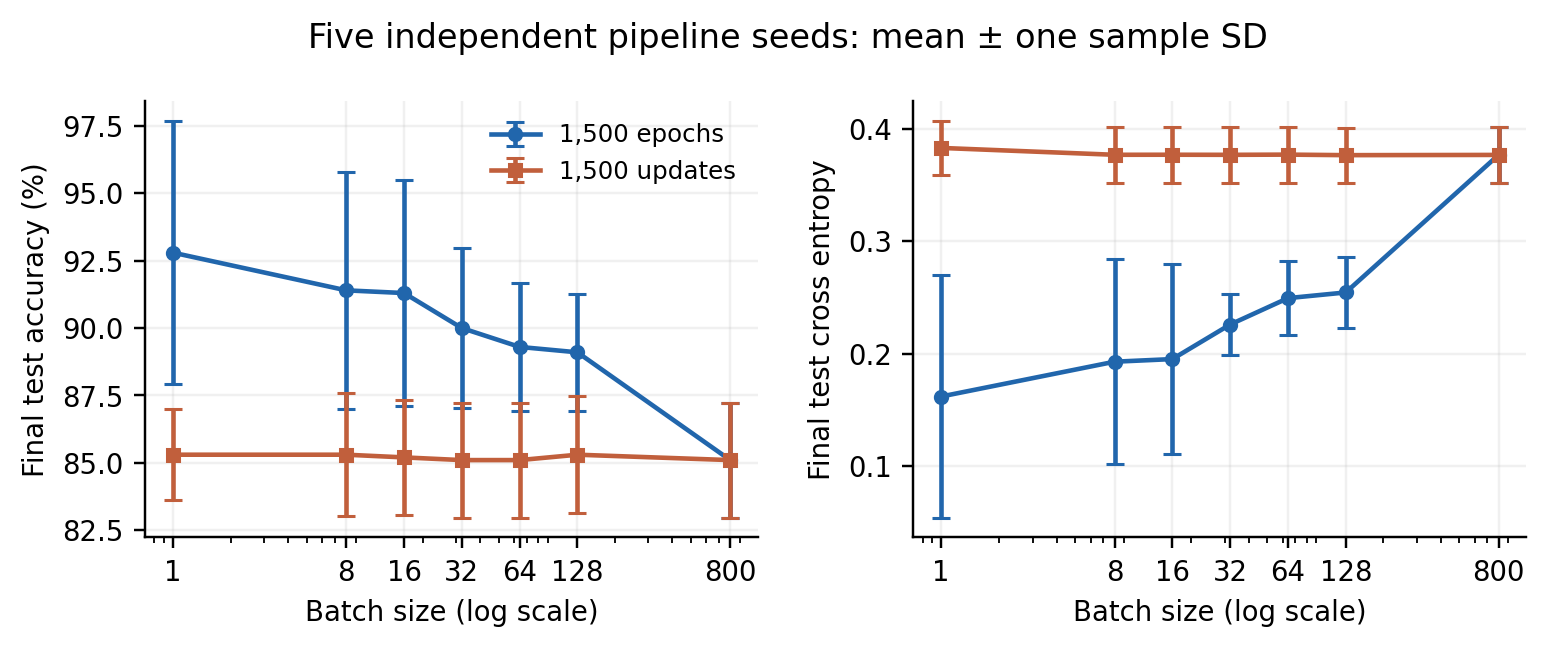

**Figure M3.** Mean final performance with ±1 sample SD across five pipeline seeds. Error bars quantify variability under each explicitly stated budget.

In [13]:
table(["Budget", "Batch", "Seeds", "Mean test accuracy", "Sample SD (percentage points)", "Mean test loss"], [
    [row["budget"], row["batch_size"], row["n_seeds"],
     f"{row['test_accuracy_mean']:.2%}", f"{row['test_accuracy_sd'] * 100:.3f}", f"{row['test_loss_mean']:.6f}"]
    for row in mlp["summary"]
])
figure("mlp_budget_comparison.png", "**Figure M3.** Mean final performance with ±1 sample SD across five pipeline seeds. Error bars quantify variability under each explicitly stated budget.")

### Extension · Inspect the learned nonlinear boundary

Accuracy alone does not show what the model learned. The following
probability surfaces show how the same architecture bends its
decision boundary around the two moons under different optimization
regimes. The black contour is the 0.5 predicted-probability boundary,
and marked test errors locate remaining failures. A smooth-looking
surface or high score on one test split does not establish that an
optimizer reaches a global optimum or that a particular batch size
generalizes best.

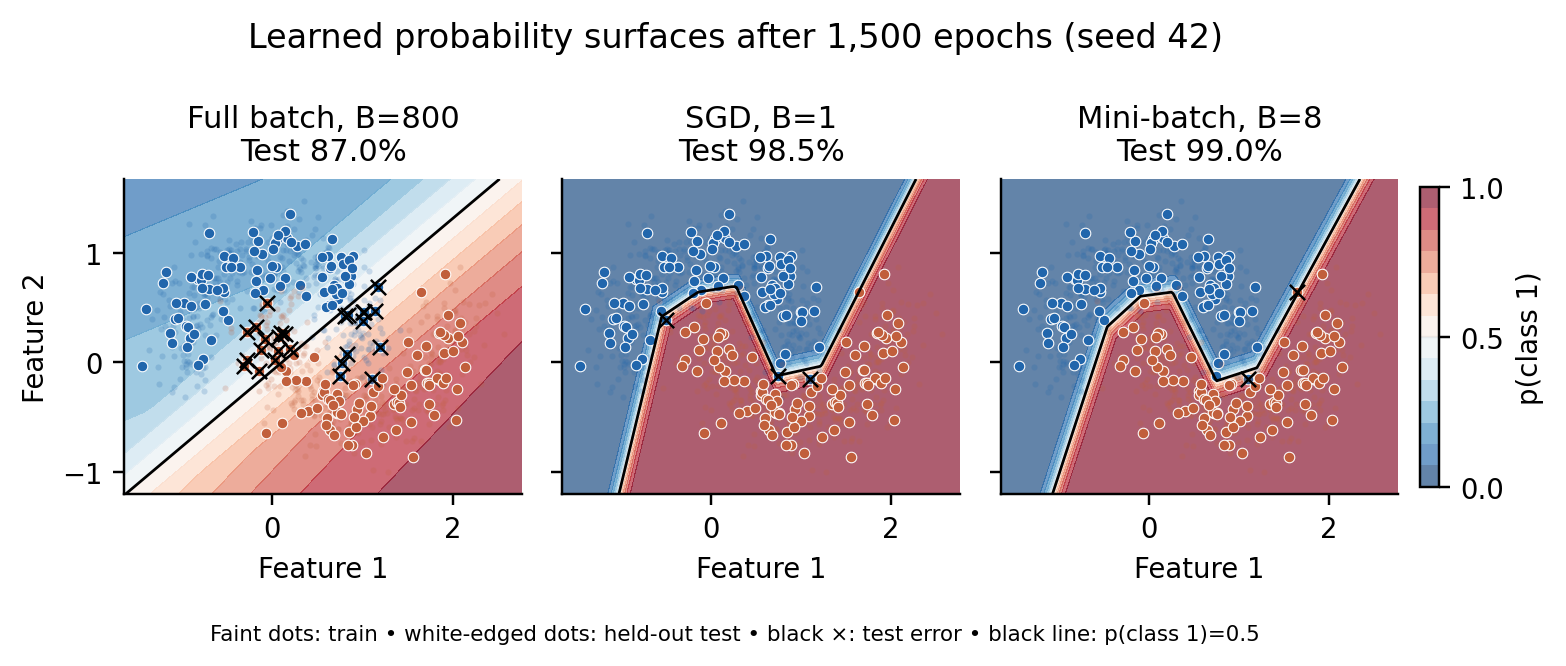

**Figure M4.** Full-batch, SGD, and mini-batch learned probability surfaces after the same 1,500 epochs, with identical seed-42 data and initialization.

In [14]:
figure("mlp_decision_surfaces.png", "**Figure M4.** Full-batch, SGD, and mini-batch learned probability surfaces after the same 1,500 epochs, with identical seed-42 data and initialization.")

## Reproducibility and scope

The baseline perceptron trajectories match the original implementation,
and the required MLP runs call the original trainer. The equal-update
extension is checked against the original full-batch model's final
parameters. Numerical derivatives verify the one-layer and deeper
MLP implementations in the tested, non-clipped regime.

The experiment scripts store exact histories, final parameters for
the plotted seed-42 models, budgets, settings, and environment details.
The written report provides interpretation alongside these figures.
No claim of guaranteed convergence on overlapping Gaussians, global
optimality for the MLP, or universally best batch size follows from
these experiments.

From the project root:

```bash
python report_revision/perceptron_experiments.py
python report_revision/mlp_experiments.py
python report_revision/make_notebook.py
python -m nbconvert --to notebook --execute --inplace report_revision/assignment1_revised.ipynb
```

To regenerate MLP figures from saved results without training:

```bash
python report_revision/mlp_experiments.py --plot-only
```

In [15]:
table(["Environment item", "Recorded value"], list(mlp["environment"].items()))
print("Recorded MLP experiment seconds:", round(mlp["compute_elapsed_seconds"], 3))
print("Result integrity fingerprints (SHA-256):")
for name in ("perceptron.json", "mlp.json"):
    print(name, hashlib.sha256((BASE / "results" / name).read_bytes()).hexdigest())
print("Notebook completed: figures and tables loaded successfully; training was skipped by default.")

Environment item,Recorded value
python,3.11.15
numpy,1.26.4
sklearn,1.3.1
matplotlib,3.10.8
threads,"{'OPENBLAS_NUM_THREADS': '1', 'OMP_NUM_THREADS': '1'}"


Recorded MLP experiment seconds: 140.254
Result integrity fingerprints (SHA-256):
perceptron.json e1da7a2e6e2cd81a0c2df9f8f221166bd2ac9796601c7867edf3fb7d6055e9b0
mlp.json 4928ebfd5be2c8cf9dbcbb52762dedd4f6993c9d66a242b0875931cf9deb1e63
Notebook completed: figures and tables loaded successfully; training was skipped by default.
